# MiniGPT: um GPT de caracteres feito do zero

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LyanKaleu/MiniGPT/blob/main/MiniGPT.ipynb)

Este notebook constrói, treina e usa um modelo de linguagem no estilo GPT usando apenas PyTorch. Nada vem pronto: a atenção, os blocos Transformer e o laço de treinamento são escritos à mão, um passo de cada vez.

O modelo é propositalmente pequeno (cerca de 30 mil parâmetros) para rodar em segundos numa CPU. A ideia é entender cada peça, não obter um modelo útil.

**Roteiro**

1. Preparar os dados: texto → caracteres → números → lotes.
2. Montar a arquitetura: atenção → multi-head → feed-forward → bloco Transformer → MiniGPT.
3. Treinar o modelo acompanhando a loss de treino e de validação.
4. Gerar texto, um caractere por vez.

# 1. Bibliotecas, dispositivo e semente

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

PyTorch: 2.15.0+cpu
Dispositivo: cpu


### Explicação

* `torch` é a biblioteca principal; `torch.nn` traz as camadas usadas para montar redes neurais; `torch.nn.functional` traz funções como `softmax`.
* `matplotlib` será usado para desenhar a curva de loss.
* `torch.manual_seed(42)` fixa o gerador de números aleatórios. Assim, os pesos iniciais, os lotes sorteados e o texto gerado saem iguais a cada execução, e os resultados podem ser reproduzidos.
* `device` vale `cuda` se houver GPU disponível e `cpu` caso contrário. Modelo e dados precisam estar no mesmo dispositivo.

# 2. Texto utilizado para o treinamento

In [2]:
text = """
Era uma vez um gato que vivia em uma pequena casa.
O gato gostava de caminhar pelo jardim.
Todos os dias o gato observava os pássaros.
Quando o sol aparecia, o gato saía de casa.
O cachorro também vivia naquela casa.
O cachorro corria pelo jardim e brincava com o gato.
O gato gostava de peixe e o cachorro gostava de carne.
À noite, os dois animais voltavam para casa.
O gato dormia perto da janela e o cachorro dormia perto da porta.
No dia seguinte, tudo começava novamente.
""" * 200

print("Número de caracteres:", len(text))
print()
print(text[:500])

Número de caracteres: 95800


Era uma vez um gato que vivia em uma pequena casa.
O gato gostava de caminhar pelo jardim.
Todos os dias o gato observava os pássaros.
Quando o sol aparecia, o gato saía de casa.
O cachorro também vivia naquela casa.
O cachorro corria pelo jardim e brincava com o gato.
O gato gostava de peixe e o cachorro gostava de carne.
À noite, os dois animais voltavam para casa.
O gato dormia perto da janela e o cachorro dormia perto da porta.
No dia seguinte, tudo começava novamente.

Era uma vez um gato 


### Explicação

O conjunto de dados é um pequeno parágrafo repetido 200 vezes (o `* 200` no fim da célula), o que dá cerca de 96 mil caracteres. `len(text)` mostra esse total e `text[:500]` exibe o começo do texto.

Neste projeto, cada **token** é um caractere individual.

> **Atenção:** como o texto é sempre o mesmo parágrafo, o modelo vai acabar *decorando* esse parágrafo em vez de aprender português de forma geral. Para um primeiro contato isso é útil, porque o treinamento é rápido e dá para conferir se o modelo aprendeu. A seção 25 discute como ir além disso.

# 3. Construção do vocabulário

In [3]:
chars = sorted(set(text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}


def encode(s):
    return [stoi[ch] for ch in s]


def decode(ids):
    return "".join(itos[i] for i in ids)


print("Vocabulário:")
print(chars)
print()
print("|V| =", vocab_size)

Vocabulário:
['\n', ' ', ',', '.', 'E', 'N', 'O', 'Q', 'T', 'a', 'b', 'c', 'd', 'e', 'g', 'h', 'i', 'j', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'x', 'z', 'À', 'á', 'ç', 'é', 'í']

|V| = 36


### Explicação

O modelo não trabalha com caracteres, e sim com números. Por isso montamos um vocabulário:

* `set(text)` elimina as repetições, e `sorted(...)` coloca os caracteres em uma ordem fixa. O resultado, `chars`, tem cada caractere diferente do texto exatamente uma vez.
* `vocab_size` é o tamanho do vocabulário, que chamamos de $|V|$.
* `stoi` (*string to integer*) leva cada caractere a um inteiro, e `itos` (*integer to string*) faz o caminho inverso.
* `encode` e `decode` aplicam essas conversões a textos inteiros.

# 4. Testando a tokenização

In [4]:
example = "gato"

encoded = encode(example)
decoded = decode(encoded)

print("Texto:       ", example)
print("Tokens:      ", encoded)
print("Reconstrução:", decoded)

Texto:        gato
Tokens:       [14, 9, 26, 21]
Reconstrução: gato


### Explicação

Conferimos que as duas conversões são inversas uma da outra: `"gato"` vira uma lista de quatro inteiros $[i_1, i_2, i_3, i_4]$, e `decode` recupera exatamente o texto original.

# 5. Transformando todo o texto em um tensor

In [5]:
data = torch.tensor(encode(text), dtype=torch.long)

print("Shape:", data.shape)
print("Primeiros 50 tokens:")
print(data[:50])

Shape: torch.Size([95800])
Primeiros 50 tokens:
tensor([ 0,  4, 24,  9,  1, 27, 19,  9,  1, 28, 13, 30,  1, 27, 19,  1, 14,  9,
        26, 21,  1, 23, 27, 13,  1, 28, 16, 28, 16,  9,  1, 13, 19,  1, 27, 19,
         9,  1, 22, 13, 23, 27, 13, 20,  9,  1, 11,  9, 25,  9])


### Explicação

Agora codificamos o texto inteiro em um tensor unidimensional $\text{data} \in \mathbb{N}^N$, em que $N$ é o número total de caracteres. Cada posição guarda o índice de um caractere no vocabulário.

Usamos `dtype=torch.long` porque `nn.Embedding`, que veremos adiante, exige índices inteiros.

# 6. Separando treinamento e validação

In [6]:
n = int(0.9 * len(data))

train_data = data[:n]
val_data = data[n:]

print("Tokens de treino:   ", len(train_data))
print("Tokens de validação:", len(val_data))

Tokens de treino:    86220
Tokens de validação: 9580


### Explicação

Os primeiros 90% dos tokens vão para o treinamento e os 10% finais para a validação. O modelo só atualiza seus parâmetros com `train_data`; `val_data` serve para medir, durante o treino, como ele se sai em trechos que nunca usou para aprender.

Aqui há uma pegadinha: como o texto é o mesmo parágrafo repetido, a validação contém exatamente as mesmas frases do treino. Voltaremos a isso quando olharmos a curva de loss.

# 7. Hiperparâmetros

In [7]:
# Arquitetura
d = 32  # dimensão do embedding
T = 64  # tamanho máximo do contexto
L = 2   # número de blocos Transformer
h = 4   # número de cabeças de atenção

# Treinamento
batch_size = 32
learning_rate = 1e-3
max_steps = 3000
eval_interval = 300  # a cada quantos passos medimos a loss
eval_iters = 50      # quantos lotes usamos em cada medição

print("|V| =", vocab_size)
print(f"d = {d}, T = {T}, L = {L}, h = {h}")
print(f"batch_size = {batch_size}, learning_rate = {learning_rate}, max_steps = {max_steps}")

|V| = 36
d = 32, T = 64, L = 2, h = 4
batch_size = 32, learning_rate = 0.001, max_steps = 3000


### Explicação

| Símbolo | Valor | Significado |
|---|---|---|
| $d$ | 32 | cada caractere é representado por um vetor de 32 números |
| $T$ | 64 | o modelo enxerga no máximo 64 caracteres de contexto |
| $L$ | 2 | quantidade de blocos Transformer empilhados |
| $h$ | 4 | quantidade de cabeças de atenção em cada bloco |
| $B$ | 32 | cada passo de treino usa 32 sequências ao mesmo tempo |

Os demais valores controlam o treinamento: a taxa de aprendizado $\eta = 10^{-3}$, o número de passos e a frequência com que medimos a loss de treino e de validação.

# 8. Construção dos lotes

In [8]:
def get_batch(split):
    source = train_data if split == "train" else val_data

    # Sorteia batch_size posições iniciais; cada uma precisa de T + 1 tokens
    starts = torch.randint(0, len(source) - T, (batch_size,))

    X = torch.stack([source[i : i + T] for i in starts])
    Y = torch.stack([source[i + 1 : i + T + 1] for i in starts])

    return X.to(device), Y.to(device)

### Explicação

A tarefa de um modelo de linguagem é **prever o próximo token**. Por isso, o alvo `Y` é a entrada `X` deslocada uma posição para a frente. Com o texto `O gato dorme`, por exemplo:

```text
X = "O gato dorm"
Y = " gato dorme"
```

Formalmente, $Y_t = X_{t+1}$: cada posição de `X` é usada para prever a posição correspondente de `Y`.

Cada exemplo precisa de $T + 1$ tokens consecutivos (os $T$ de `X` e mais um no fim de `Y`), então a posição inicial é sorteada entre $0$ e $N - T - 1$. A função já devolve os tensores no dispositivo certo.

# 9. Visualizando um batch

In [9]:
X, Y = get_batch("train")

print("X.shape =", X.shape)
print("Y.shape =", Y.shape)
print()
print("Primeira entrada:")
print(decode(X[0].tolist()))
print()
print("Primeiro alvo:")
print(decode(Y[0].tolist()))

X.shape = torch.Size([32, 64])
Y.shape = torch.Size([32, 64])

Primeira entrada:
horro também vivia naquela casa.
O cachorro corria pelo jardim e

Primeiro alvo:
orro também vivia naquela casa.
O cachorro corria pelo jardim e 


### Explicação

Com $B = 32$ e $T = 64$, esperamos `X.shape = Y.shape = (32, 64)`: 32 sequências de 64 tokens. Decodificar a primeira linha de cada tensor mostra o deslocamento de um caractere entre a entrada e o alvo.

# 10. Uma cabeça de atenção

In [10]:
class Head(nn.Module):
    def __init__(self, d, head_dim, T):
        super().__init__()
        self.key = nn.Linear(d, head_dim, bias=False)
        self.query = nn.Linear(d, head_dim, bias=False)
        self.value = nn.Linear(d, head_dim, bias=False)
        self.register_buffer("mask", torch.tril(torch.ones(T, T)))
        self.head_dim = head_dim

    def forward(self, x):
        Q = self.query(x)  # (B, T, head_dim)
        K = self.key(x)    # (B, T, head_dim)
        V = self.value(x)  # (B, T, head_dim)

        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.head_dim)  # (B, T, T)

        T_current = x.size(1)
        mask = self.mask[:T_current, :T_current]
        scores = scores.masked_fill(mask == 0, float("-inf"))

        A = F.softmax(scores, dim=-1)
        return A @ V  # (B, T, head_dim)

### Explicação

Esta classe implementa uma cabeça de **atenção causal**. A entrada tem forma $(B, T, d)$, e cada vetor é projetado em três representações:

$$Q = XW_Q, \qquad K = XW_K, \qquad V = XW_V$$

* a **Query** ($Q$) diz o que uma posição está procurando;
* a **Key** ($K$) diz o que cada posição oferece;
* o **Value** ($V$) é a informação que será efetivamente repassada.

O produto $QK^\top$ mede a afinidade entre cada par de posições. Dividimos por $\sqrt{d_{head}}$ para manter esses valores numa escala razoável; sem isso, o softmax ficaria saturado.

A máscara triangular (`torch.tril`) impede que uma posição olhe para o futuro: para prever o caractere seguinte à posição $t$, o modelo só pode usar as posições $1, \dots, t$. As posições proibidas recebem $-\infty$, que vira probabilidade zero no softmax.

Juntando tudo:

$$\text{out} = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_{head}}}\right) V$$

Essa é a operação central do Transformer.

# 11. Multi-Head Attention

In [11]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d, h, T):
        super().__init__()
        assert d % h == 0, "d precisa ser divisível por h"
        head_dim = d // h
        self.heads = nn.ModuleList([Head(d, head_dim, T) for _ in range(h)])
        self.projection = nn.Linear(d, d)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)  # (B, T, d)
        return self.projection(out)

### Explicação

Em vez de uma única cabeça, usamos $h = 4$ cabeças em paralelo, cada uma livre para prestar atenção a padrões diferentes. Para manter o custo, cada cabeça trabalha numa dimensão menor:

$$d_{head} = \frac{d}{h} = \frac{32}{4} = 8$$

Concatenando as saídas das quatro cabeças ($8 + 8 + 8 + 8$), voltamos à dimensão $d = 32$. A projeção linear final combina o que cada cabeça encontrou.

# 12. Feed-Forward Network

In [12]:
class FeedForward(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d, 4 * d),
            nn.GELU(),
            nn.Linear(4 * d, d),
        )

    def forward(self, x):
        return self.net(x)

### Explicação

Depois da atenção, cada posição passa por uma pequena rede neural: uma camada que expande a dimensão de $d = 32$ para $4d = 128$, a ativação GELU e uma camada que volta para $32$.

A divisão de tarefas é esta: a **atenção** mistura informação *entre* posições; a **feed-forward** processa *cada* posição separadamente.

# 13. Bloco Transformer

In [13]:
class TransformerBlock(nn.Module):
    def __init__(self, d, h, T):
        super().__init__()
        self.ln1 = nn.LayerNorm(d)
        self.attention = MultiHeadAttention(d, h, T)
        self.ln2 = nn.LayerNorm(d)
        self.ffn = FeedForward(d)

    def forward(self, x):
        x = x + self.attention(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

### Explicação

O bloco junta os dois componentes, cada um precedido de uma normalização (LayerNorm) e envolvido por uma **conexão residual**:

$$x \leftarrow x + \text{Attention}(\text{LayerNorm}(x))$$
$$x \leftarrow x + \text{FFN}(\text{LayerNorm}(x))$$

As somas com $x$ são as conexões residuais: cada componente só precisa aprender uma *correção* sobre a entrada, o que facilita o treinamento de redes mais profundas. Normalizar antes de cada componente (*pre-norm*) é a variante usada pelo GPT-2 em diante.

# 14. Construindo o MiniGPT

In [14]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size, d, T, L, h):
        super().__init__()
        self.T = T
        self.token_embedding = nn.Embedding(vocab_size, d)
        self.position_embedding = nn.Embedding(T, d)
        self.blocks = nn.ModuleList([TransformerBlock(d, h, T) for _ in range(L)])
        self.ln_final = nn.LayerNorm(d)
        self.lm_head = nn.Linear(d, vocab_size)

    def forward(self, idx):
        B, T_current = idx.shape

        token_emb = self.token_embedding(idx)  # (B, T, d)
        positions = torch.arange(T_current, device=idx.device)
        position_emb = self.position_embedding(positions)  # (T, d)

        x = token_emb + position_emb
        for block in self.blocks:
            x = block(x)

        x = self.ln_final(x)
        return self.lm_head(x)  # (B, T, |V|)

### Explicação

Esta é a arquitetura completa:

1. O **token embedding** transforma cada índice num vetor de $\mathbb{R}^{32}$.
2. O **position embedding** gera um vetor para cada posição. Sem ele, a atenção não saberia a ordem dos caracteres.
3. Somamos os dois: $x = \text{token embedding} + \text{position embedding}$.
4. $x$ passa pelos $L = 2$ blocos Transformer.
5. Uma última LayerNorm (`ln_final`) e uma camada linear (`lm_head`) levam cada vetor de $\mathbb{R}^{32}$ para $\mathbb{R}^{|V|}$.

Para cada posição, o modelo produz $|V|$ números chamados **logits**: uma pontuação para cada caractere possível como próximo token.

# 15. Instanciando o modelo

In [15]:
model = MiniGPT(vocab_size=vocab_size, d=d, T=T, L=L, h=h).to(device)

print(model)

num_parameters = sum(p.numel() for p in model.parameters())
print(f"\nNúmero de parâmetros: {num_parameters:,}")

MiniGPT(
  (token_embedding): Embedding(36, 32)
  (position_embedding): Embedding(64, 32)
  (blocks): ModuleList(
    (0-1): 2 x TransformerBlock(
      (ln1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (attention): MultiHeadAttention(
        (heads): ModuleList(
          (0-3): 4 x Head(
            (key): Linear(in_features=32, out_features=8, bias=False)
            (query): Linear(in_features=32, out_features=8, bias=False)
            (value): Linear(in_features=32, out_features=8, bias=False)
          )
        )
        (projection): Linear(in_features=32, out_features=32, bias=True)
      )
      (ln2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (ffn): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=32, out_features=128, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=128, out_features=32, bias=True)
        )
      )
    )
  )
  (ln_final): LayerNorm((32,), e

### Explicação

Criamos o modelo com os hiperparâmetros definidos antes e o movemos para o dispositivo com `.to(device)`. Somando `p.numel()` de todos os tensores de pesos, obtemos quantos números o treinamento poderá ajustar. Para comparar: o GPT-2 pequeno tem 124 milhões de parâmetros.

# 16. Primeiro forward pass

In [16]:
X, Y = get_batch("train")
logits = model(X)

print("X:     ", X.shape)
print("logits:", logits.shape)
print("Y:     ", Y.shape)

X:      torch.Size([32, 64])
logits: torch.Size([32, 64, 36])
Y:      torch.Size([32, 64])


### Explicação

Enviamos um lote ao modelo ainda sem treino. A entrada $X \in \mathbb{N}^{B \times T}$ tem forma $(32, 64)$ e a saída tem forma $(32, 64, |V|)$: para cada uma das 32 sequências e cada uma das 64 posições, uma pontuação para cada caractere do vocabulário.

# 17. Calculando a loss inicial

In [17]:
loss_fn = nn.CrossEntropyLoss()

loss = loss_fn(logits.reshape(-1, vocab_size), Y.reshape(-1))

print(f"Loss inicial:                           {loss.item():.4f}")
print(f"Esperado para um chute uniforme, ln|V|: {math.log(vocab_size):.4f}")

Loss inicial:                           3.7348
Esperado para um chute uniforme, ln|V|: 3.5835


### Explicação

A `CrossEntropyLoss` mede o quanto a distribuição prevista se afasta do caractere correto. Ela espera os logits em forma $(N, |V|)$ e os alvos em forma $(N)$, então "achatamos" os tensores: $(B, T, |V|) \to (BT, |V|)$ e $(B, T) \to (BT)$. Cada uma das $B \times T$ posições vira uma previsão independente.

Há um bom teste de sanidade aqui. Com pesos aleatórios, o modelo espalha a probabilidade de forma quase uniforme, $1/|V|$ para cada caractere, e a loss esperada é

$$-\ln\frac{1}{|V|} = \ln |V| = \ln 36 \approx 3{,}58.$$

Se a loss inicial estiver muito acima disso, há algo errado na inicialização.

# 18. Otimizador e avaliação

In [18]:
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)


@torch.no_grad()
def estimate_loss():
    """Loss média de treino e de validação, calculada em vários lotes."""
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits = model(X)
            losses[k] = loss_fn(logits.reshape(-1, vocab_size), Y.reshape(-1)).item()
        out[split] = losses.mean().item()
    model.train()
    return out

### Explicação

O **AdamW** é o otimizador que atualizará os parâmetros, com taxa de aprendizado $\eta = 10^{-3}$.

A função `estimate_loss` mede a loss em `eval_iters` lotes de treino e de validação e devolve a média. A loss de um único lote oscila bastante; a média de vários lotes dá uma curva mais confiável. O decorador `@torch.no_grad()` desliga o cálculo de gradientes, que não é necessário só para medir, e `model.eval()` / `model.train()` alternam o modo do modelo.

# 19. Treinamento

In [19]:
history = []

for step in range(max_steps + 1):
    if step % eval_interval == 0:
        losses = estimate_loss()
        history.append({"step": step, **losses})
        print(f"step {step:4d} | treino {losses['train']:.4f} | validação {losses['val']:.4f}")

    if step == max_steps:
        break

    X, Y = get_batch("train")
    logits = model(X)
    loss = loss_fn(logits.reshape(-1, vocab_size), Y.reshape(-1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

step    0 | treino 3.7389 | validação 3.7331


step  300 | treino 1.4193 | validação 1.4173


step  600 | treino 0.5290 | validação 0.5292


step  900 | treino 0.1973 | validação 0.1928


step 1200 | treino 0.1084 | validação 0.1077


step 1500 | treino 0.0825 | validação 0.0809


step 1800 | treino 0.0717 | validação 0.0719


step 2100 | treino 0.0676 | validação 0.0685


step 2400 | treino 0.0653 | validação 0.0651


step 2700 | treino 0.0611 | validação 0.0611


step 3000 | treino 0.0619 | validação 0.0623


### Explicação

Esta é a etapa em que o modelo aprende. Cada passo repete o mesmo ciclo:

1. sortear um lote novo (`get_batch`);
2. calcular as previsões (`model(X)`);
3. medir o erro (`loss_fn`);
4. zerar os gradientes do passo anterior (`optimizer.zero_grad()`);
5. calcular os novos gradientes por *backpropagation* (`loss.backward()`);
6. atualizar os parâmetros (`optimizer.step()`).

Em resumo: **X → modelo → logits → loss → gradientes → atualização**, repetido 3000 vezes. A cada `eval_interval` passos, guardamos a loss de treino e de validação em `history`.

# 20. Curva de aprendizado

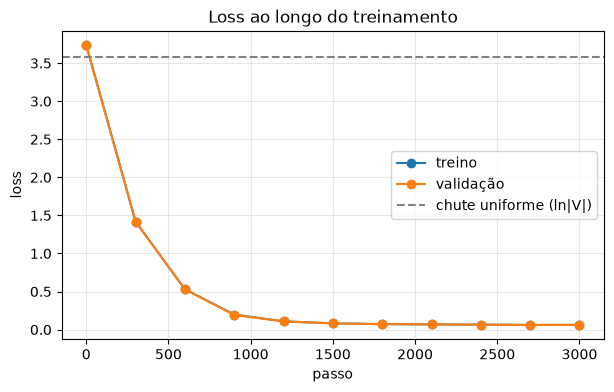

In [20]:
steps = [entry["step"] for entry in history]

plt.figure(figsize=(7, 4))
plt.plot(steps, [entry["train"] for entry in history], marker="o", label="treino")
plt.plot(steps, [entry["val"] for entry in history], marker="o", label="validação")
plt.axhline(math.log(vocab_size), color="gray", linestyle="--", label="chute uniforme (ln|V|)")
plt.xlabel("passo")
plt.ylabel("loss")
plt.title("Loss ao longo do treinamento")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Explicação

As duas curvas descem juntas e quase se sobrepõem. A loss estabiliza perto de 0,06 em vez de chegar a zero: no começo de cada janela o modelo vê pouquíssimos caracteres e não tem como saber em que ponto do parágrafo está.

Num problema real, isso indicaria que o modelo generaliza bem. **Aqui não é o caso**: a validação contém exatamente as mesmas frases do treino (o parágrafo repetido), então uma loss de validação baixa só confirma que o modelo decorou o parágrafo.

Com um texto variado, o normal seria a curva de validação ficar acima da de treino e, em algum momento, parar de cair ou até subir. Esse é o sinal de *overfitting* que a validação existe para detectar.

# 21. Função de geração

In [21]:
@torch.no_grad()
def generate(model, idx, max_new_tokens):
    model.eval()
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -model.T :]  # mantém somente os últimos T tokens
        logits = model(idx_cond)
        logits = logits[:, -1, :]  # só a última posição prevê o próximo token
        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)  # sorteia o próximo token
        idx = torch.cat([idx, next_token], dim=1)
    model.train()
    return idx

### Explicação

A geração é **autorregressiva**: o modelo prevê um caractere, esse caractere entra no contexto, e o processo se repete.

A cada iteração:

1. cortamos o contexto para os últimos $T$ tokens, porque o position embedding só conhece $T$ posições;
2. calculamos os logits e ficamos só com os da última posição, que estimam $P(x_{t+1} \mid x_1, \dots, x_t)$;
3. transformamos os logits em probabilidades com softmax, $p_i = e^{z_i} / \sum_j e^{z_j}$;
4. sorteamos o próximo caractere com `torch.multinomial`, de acordo com essas probabilidades;
5. acrescentamos o caractere sorteado à sequência.

Sortear, em vez de escolher sempre o mais provável, é o que permite que o mesmo prompt gere textos diferentes.

# 22. Investigando a próxima previsão

In [22]:
prompt = "ca"
idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)

with torch.no_grad():
    logits = model(idx)
    probs = F.softmax(logits[0, -1, :], dim=-1)  # distribuição do próximo caractere

top_probs, top_ids = torch.topk(probs, k=10)

for p, token_id in zip(top_probs, top_ids):
    print(repr(itos[token_id.item()]), f"{p.item():.4f}")

's' 0.3258
'c' 0.2835
'r' 0.1379
'v' 0.1072
'm' 0.1052
' ' 0.0108
'n' 0.0098
'i' 0.0081
'.' 0.0080
'O' 0.0013


### Explicação

Antes de gerar uma sequência inteira, vale olhar uma única previsão. Enviamos o prompt `"ca"` e pegamos a distribuição de probabilidade da última posição; `torch.topk` lista os dez caracteres mais prováveis.

Dá para conferir se o resultado faz sentido. Em cada repetição do parágrafo, "ca" começa **ca**chorro 5 vezes, **ca**sa 4 vezes, **ca**minhar e **ca**rne uma vez cada. Esperamos então `s` e `c` dividindo o topo, com `m` e `r` logo abaixo.

O modelo também dá um pouco de probabilidade a outras letras, como `v`. Isso acontece porque ele vê só dois caracteres e não sabe se "ca" é o começo de uma palavra ou o meio dela, como em brin**cav**a.

# 23. Geração de texto

In [23]:
prompt = "O g"
idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)

generated = generate(model, idx, max_new_tokens=300)
print(decode(generated[0].tolist()))

O gato dormia perto da porta.
No dia seguinte, tudo começava novameçava namente.

Era uma vez um gato que vivia em uma pequena casa.
O gato gostava de caminhar pelo jardim.
Todos os dias o gato observava os píarequela m vinm.
Era va uma gatela parto casa.
O gato dormiva pera deia pelo jardim e brina pe


### Explicação

Partindo do prompt `"O g"`, geramos 300 caracteres novos e decodificamos o resultado. Boa parte do texto reproduz frases inteiras do parágrafo de treino, o que confirma que toda a cadeia funciona. Não é criatividade: o modelo só sabe continuar esse parágrafo.

Também aparecem trechos embaralhados. Como cada caractere é *sorteado*, de vez em quando sai uma letra pouco provável. A partir daí o contexto contém algo que o modelo nunca viu no treino, as previsões seguintes pioram e os erros se acumulam até ele "reencontrar" uma frase conhecida. Esse efeito de erros que se propagam existe em qualquer modelo autorregressivo; técnicas como temperatura e top-k (seção 25) ajudam a controlá-lo.

# 24. Visão geral da arquitetura

```text
texto
  │
  ▼
caracteres → índices
  │
  ▼
X ∈ ℕ^(B×T)
  │
  ▼
Token Embedding + Position Embedding
  │
  ▼
Transformer Block  ×L
  (LayerNorm → Multi-Head Attention → +residual,
   LayerNorm → Feed-Forward → +residual)
  │
  ▼
LayerNorm → Linear
  │
  ▼
logits ∈ ℝ^(B×T×|V|)
  │
  ▼
CrossEntropyLoss
```

**Treinamento:** loss → backpropagation → AdamW → novos parâmetros.

**Geração:** prompt → logits → softmax → amostragem → novo token → novo contexto → …

O resultado é um GPT completo, embora deliberadamente pequeno: caracteres como tokens, $d = 32$, $L = 2$ blocos e $h = 4$ cabeças de atenção.

# 25. Limitações e próximos passos

**O que este notebook não mostra.** O modelo decorou um único parágrafo. A loss de validação baixa não prova generalização, porque treino e validação têm o mesmo texto.

**Ideias para continuar:**

* **Treinar com um texto de verdade.** Um livro em domínio público, como *Dom Casmurro*, de Machado de Assis, tem vocabulário e estilo variados. A curva de validação passa a significar algo, e vale aumentar $d$, $L$, $h$ e $T$ e acrescentar *dropout*.
* **Controlar a amostragem.** Acrescentar à função `generate` uma **temperatura** (dividir os logits por um valor $\tau$ antes do softmax) e **top-k** (sortear só entre os $k$ caracteres mais prováveis).
* **Atenção mais eficiente.** Substituir o laço de cabeças por uma única multiplicação de matrizes, ou por `F.scaled_dot_product_attention`, que o PyTorch otimiza.
* **Tokenização por subpalavras.** Trocar caracteres por tokens BPE, como fazem os GPTs reais.

**Referências**

* Vaswani et al., [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762) (2017): o artigo que introduziu o Transformer.
* Radford et al., [*Language Models are Unsupervised Multitask Learners*](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf) (2019): o artigo do GPT-2.
* Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) e o repositório [nanoGPT](https://github.com/karpathy/nanoGPT).